In [8]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [10]:
caminho = '/home/lucas/Documentos/GitHub/projeto-extensionista-cpa/dados'
df = pd.read_json(f"{caminho}/dados_limpos.json",orient='index')

/tmp/ipykernel_50728/2922978596.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_10.values, y=top_10.index, palette='Reds_r')


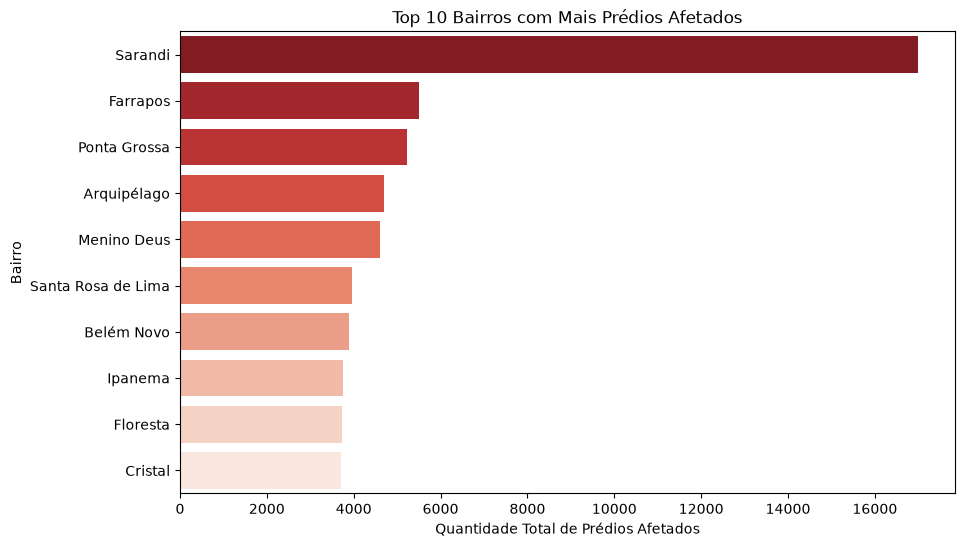

In [17]:
plt.figure(figsize=(10, 6))

# Calculamos os valores máximos em uma variável separada (Series), sem tocar no df
serie_afetados = df['affected_buildings'].apply(lambda x: max(x) if len(x) > 0 else 0)
top_10 = serie_afetados.nlargest(10)

# Passamos os valores (x) e o índice com os nomes (y) para o Seaborn
sns.barplot(x=top_10.values, y=top_10.index, palette='Reds_r')

plt.title("Top 10 Bairros com Mais Prédios Afetados")
plt.xlabel("Quantidade Total de Prédios Afetados")
plt.ylabel("Bairro")
plt.show()

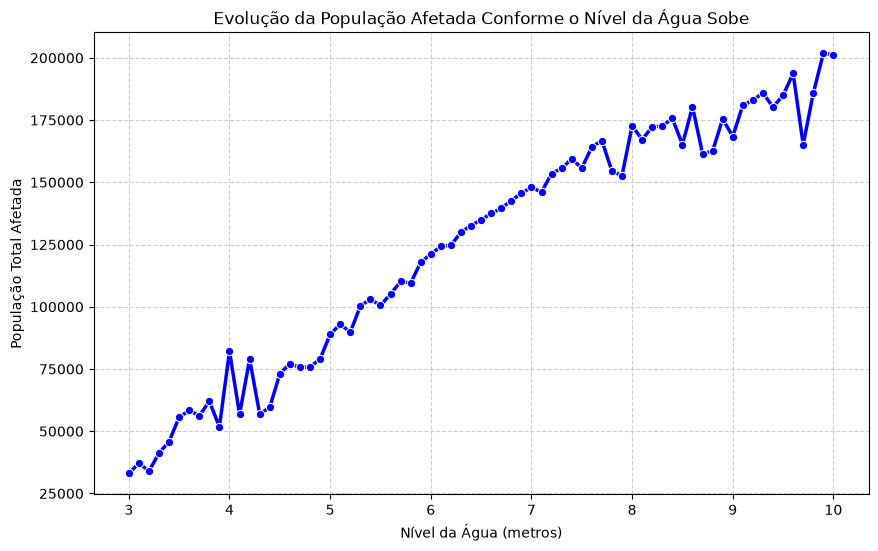

In [ ]:
dados_por_nivel = {}

for dic in df['affected_population']:
    if isinstance(dic, dict):
        for nivel, qtd in dic.items():
            dados_por_nivel[nivel] = dados_por_nivel.get(nivel, 0) + qtd

df_nivel_agua = pd.DataFrame(list(dados_por_nivel.items()), columns=['nivel_str', 'populacao_afetada'])

df_nivel_agua['nivel_num'] = df_nivel_agua['nivel_str'].str.replace('_', '.').str.replace('m', '').astype(float)
df_nivel_agua = df_nivel_agua.sort_values('nivel_num')

plt.figure(figsize=(10, 6))

sns.lineplot(
    data=df_nivel_agua, 
    x='nivel_num', 
    y='populacao_afetada', 
    marker='o', 
    color='b', 
    linewidth=2.5
)

plt.title("Evolução da População Afetada Conforme o Nível da Água Sobe")
plt.xlabel("Nível da Água (metros)")
plt.ylabel("População Total Afetada")
plt.grid(True, linestyle='--', alpha=0.6)

plt.show()